# Multi-Agent Q-Learning: Coordination in a Grid World

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Reinforcement learning/Tabular Q-learning agent.ipynb)

# Grid environment

In [127]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Parameters
GRID_SIZE = 5
N_AGENTS = 4
ACTIONS = ['N', 'S', 'E', 'W']
ACTION_TO_DELTA = {'N': (-1, 0), 'S': (1, 0), 'E': (0, 1), 'W': (0, -1)}
MAX_STEPS = 1_500_000
COLLISION_BUDGET = 4000
EPSILON_START = 1.0
EPSILON_MIN = 0.1
EPSILON_DECAY = 0.999995
ALPHA = 0.1
GAMMA = 0.95

# Helper functions
def clamp(x):
    return max(0, min(GRID_SIZE-1, x))

def random_pos():
    return (np.random.randint(0, GRID_SIZE), np.random.randint(0, GRID_SIZE))

def encode_state(agent_pos, carrying, A, B):
    # (x, y, carrying, Ax, Ay, Bx, By)
    return (agent_pos[0], agent_pos[1], carrying, A[0], A[1], B[0], B[1])

# Environment
class GridEnv:
    def __init__(self):
        self.A, self.B = random_pos(), random_pos()
        while self.A == self.B:
            self.B = random_pos()
        self.agent_states = []
        self.reset_agents()
        self.collisions = 0
        self.deliveries = 0
        self.clock = 0
    def reset_agents(self):
        # Place each agent at A or B, randomise
        self.agent_states = []
        for _ in range(N_AGENTS):
            start = self.A if np.random.rand() < 0.5 else self.B
            carrying = int(start == self.A)
            self.agent_states.append({'pos': start, 'carrying': carrying, 'direction': 'A2B' if carrying else 'B2A'})

    def step(self, actions):
        # Actions: list of action indices for each agent
        rewards = np.zeros(N_AGENTS)
        next_states = []
        positions = []
        directions = []
        # Move all agents
        for i, action_idx in enumerate(actions):
            action = ACTIONS[action_idx]
            dx, dy = ACTION_TO_DELTA[action]
            x, y = self.agent_states[i]['pos']
            nx, ny = clamp(x+dx), clamp(y+dy)
            positions.append((nx, ny))
            carrying = self.agent_states[i]['carrying']
            # Direction: A2B if carrying, B2A if not
            direction = 'A2B' if carrying else 'B2A'
            directions.append(direction)
            next_states.append({'pos': (nx, ny), 'carrying': carrying, 'direction': direction})

        # Handle pickups/dropoffs
        for i, s in enumerate(next_states):
            if s['pos'] == self.A and self.agent_states[i]['carrying'] == 0:
                s['carrying'] = 1
                s['direction'] = 'A2B'
            elif s['pos'] == self.B and self.agent_states[i]['carrying'] == 1:
                s['carrying'] = 0
                s['direction'] = 'B2A'

        # Handle rewards
        for i, s in enumerate(next_states):
            # Delivery
            if s['pos'] == self.B and self.agent_states[i]['carrying'] == 1:
                rewards[i] += 5
                self.deliveries += 1
            # Small step penalty
            rewards[i] -= 0.01

        # Handle head-on collisions (not at A or B)
        for i in range(N_AGENTS):
            for j in range(i+1, N_AGENTS):
                if next_states[i]['pos'] == next_states[j]['pos']:
                    # Only care if one is A2B and one is B2A, and not at A or B
                    if next_states[i]['direction'] != next_states[j]['direction']:
                        if next_states[i]['pos'] != self.A and next_states[i]['pos'] != self.B:
                            rewards[i] -= 1
                            rewards[j] -= 1
                            self.collisions += 1

        # Update agent states
        self.agent_states = next_states
        return rewards

    def get_obs(self, agent_idx):
        s = self.agent_states[agent_idx]
        return encode_state(s['pos'], s['carrying'], self.A, self.B)

    def is_done(self):
        # Infinite task, never done
        return False

    def reset_agents_at_B(self):
        """For testing: place all agents at B, not carrying."""
        self.agent_states = []
        for _ in range(N_AGENTS):
            self.agent_states.append({
                'pos': self.B,
                'carrying': 0,
                'direction': 'B2A'
            })


**class GridEnv
Purpose: This class defines the environment for the grid world, including agent locations, the pickup (A) and drop-off (B) points, and logic for agent movement and collisions.**

***__init__(self)
Initializes the environment:***

***GRID_SIZE: size of the grid (default is 5x5).***

N_AGENTS: number of agents (4).

agent_states: stores each agent’s current position and whether they are carrying an item.

A, B: pickup and drop-off locations, randomly chosen (ensuring they aren’t the same).

collision_count: tracks head-on collisions between agents.

***reset_agents(self)***

Resets all agents to a new state.

Repositions them to either A or B randomly.

Clears any items being carried and resets the collision count.

***step(self, actions)***

Takes a list of agent actions (each in {0: up, 1: down, 2: left, 3: right}).

Calculates each agent’s intended move.

Detects head-on collisions: if one agent goes from A→B and another B→A and they cross paths, this counts as a head-on collision.

Updates agent positions and carrying states:

Picks up item at A.

Drops off item at B.

Returns: reward for each agent (based on successful delivery), collision count, and new states.

***clamp(x)***

Ensures a coordinate remains within grid boundaries [0, GRID_SIZE-1].

***random_pos()***

Generates a random position within the grid, used to initialize A and B.

***encode_state(agent_pos, carrying, A, B)***

Encodes the full agent state.

***reset_agents(self)***

Resets all agents to either A or B.

Assigns carrying = 1 if starting at A, otherwise 0.

Direction is set to A2B or B2A accordingly.

***get_obs(self, agent_idx)***

Returns encoded state for a specific agent, to be used by the Q-table.

***is_done(self)***

Always returns False, as the task is non-episodic — agents should learn to shuttle indefinitely between A and B.

***reset_agents_at_B(self)***

Used for evaluation:

Places all agents at location B, not carrying anything.

Simulates a cold start to check whether agents can learn to deliver efficiently.







#  Q-table implementation

In [128]:
# Q-Table
class QTable:
    def __init__(self):
        self.table = {}

    def get(self, state, action):
        return self.table.get((state, action), 0.0)

    def set(self, state, action, value):
        self.table[(state, action)] = value

    def best_action(self, state):
        qs = [self.get(state, a) for a in range(4)]
        maxq = max(qs)
        return np.random.choice([i for i, q in enumerate(qs) if q == maxq])

    def update(self, state, action, reward, next_state, alpha, gamma):
        q = self.get(state, action)
        max_next = max([self.get(next_state, a) for a in range(4)])
        new_q = q + alpha * (reward + gamma * max_next - q)
        self.set(state, action, new_q)

***class QTable — Tabular Q-Learning Agent***

***This class implements a basic tabular Q-learning mechanism, where state-action values (Q-values) are stored and updated in a Python dictionary.***

***__init__(self)***
Initializes an empty dictionary.

Keys are tuples of (state, action) and values are floating-point Q-values.

***get(self, state, action)***

Returns the Q-value for a given state-action pair.

Defaults to 0.0 if the pair hasn’t been seen before (i.e., not in the table).

***set(self, state, action, value)***

Updates the Q-value for a specific (state, action) pair.

***best_action(self, state)***

Computes the best action from the current state:

Evaluates Q-values for all 4 possible actions (N, S, E, W).

Returns a randomly chosen action among those with the maximum Q-value (to break ties).

***update(self, state, action, reward, next_state, alpha, gamma)***

Performs the standard Q-learning update:

𝑄
(
𝑠
,
𝑎
)
←
𝑄
(
𝑠
,
𝑎
)
+
𝛼
(
𝑟
+
𝛾
⋅
max
⁡
𝑎
′
𝑄
(
𝑠
′
,
𝑎
′
)
−
𝑄
(
𝑠
,
𝑎
)
)

alpha is the learning rate, controlling how much new information overrides old.

gamma is the discount factor, valuing future rewards.

Updates the table with the new Q-value.




# Evaluation and training

In [129]:
def evaluate_agents(qtable, env, max_steps=20):
    env.reset_agents_at_B()
    completed = [False] * N_AGENTS
    start_collisions = env.collisions
    for _ in range(max_steps):
        actions = []
        for idx in range(N_AGENTS):
            state = env.get_obs(idx)
            action = qtable.best_action(state)  # greedy action
            actions.append(action)
        env.step(actions)
        for i in range(N_AGENTS):
            agent = env.agent_states[i]
            if agent['carrying'] == 0 and agent['pos'] == env.B:
                completed[i] = True
        if env.collisions > start_collisions:
            return False
        if all(completed):
            return True
    return False

def train():
    qtable = QTable()
    epsilon = EPSILON_START
    step = 0
    env = GridEnv()
    collision_history = []
    delivery_history = []

    while step < MAX_STEPS and env.collisions < COLLISION_BUDGET:
        env.A, env.B = random_pos(), random_pos()
        while env.A == env.B:
            env.B = random_pos()
        env.reset_agents()

        for _ in range(100):  # episode length
            agent_order = np.random.permutation(N_AGENTS)
            actions = [0]*N_AGENTS
            for idx in agent_order:
                state = env.get_obs(idx)
                if np.random.rand() < epsilon:
                    action = np.random.randint(0, 4)
                else:
                    action = qtable.best_action(state)
                actions[idx] = action
            rewards = env.step(actions)
            for idx in agent_order:
                state = env.get_obs(idx)
                action = actions[idx]
                next_state = env.get_obs(idx)
                qtable.update(state, action, rewards[idx], next_state, ALPHA, GAMMA)
            step += N_AGENTS
            if step % 10000 == 0:
                collision_history.append(env.collisions)
                delivery_history.append(env.deliveries)
            epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)
            if env.collisions >= COLLISION_BUDGET:
                break

    # Evaluation phase
    success_trials = 0
    total_evals = 100
    eval_env = GridEnv()
    for _ in range(total_evals):
        eval_env.A, eval_env.B = random_pos(), random_pos()
        while eval_env.A == eval_env.B:
            eval_env.B = random_pos()
        if evaluate_agents(qtable, eval_env):
            success_trials += 1

    success_rate = success_trials / total_evals
    total_collisions = env.collisions

    print("========== Training Summary ==========")
    print(f"Total collisions during training: {total_collisions}")
    print(f"Success rate after training: {success_rate * 100:.2f}%")

    if success_rate > 0.95 and total_collisions < 500:
        print("Performance Points: 2")
    elif success_rate > 0.85 and total_collisions < 1000:
        print("Performance Points: 1")


    return qtable, collision_history, delivery_history


***evaluate_agents(qtable, env, max_steps=20)***

This function tests whether all agents can complete one successful delivery starting from point B without any collisions. It evaluates agent behavior in a controlled scenario and returns True if all agents succeed within the step limit and without head-on collisions.

***train()***

This is the main training loop for learning agent policies using tabular Q-learning:

Agents are trained across many episodes with varying positions of A and B.

Actions are chosen using an ε-greedy policy and Q-values are updated accordingly.

Collisions and deliveries are tracked to assess training progress.

The function also runs an evaluation phase across 100 randomized test scenarios to compute a final success rate.

Based on the results, performance points are assigned per the assignment grading criteria.

Returns the final Q-table and logs of cumulative collisions and deliveries over time.

# Metric visualisation

========== Training Summary ==========
Total collisions during training: 4000
Success rate after training: 49.00%


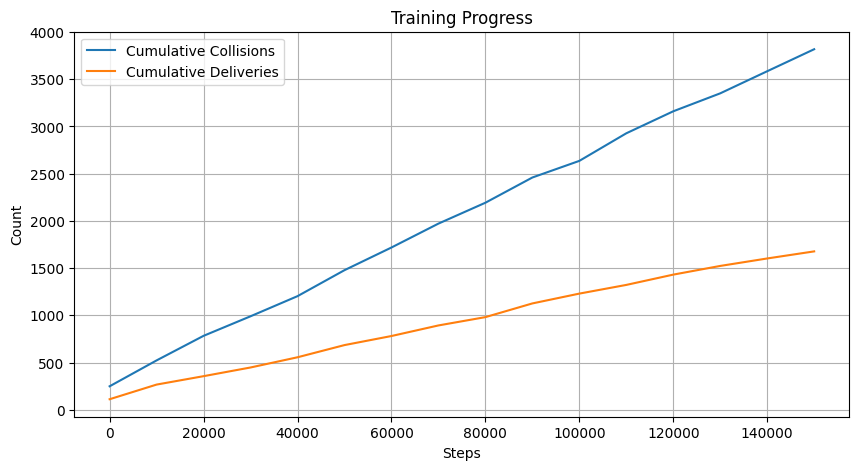

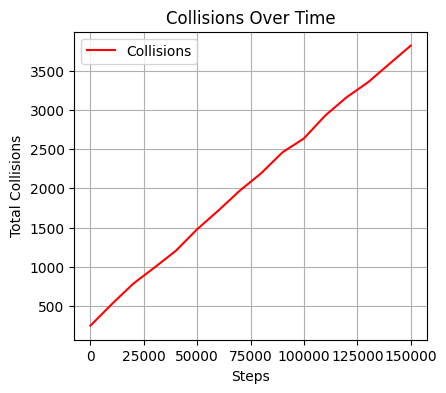

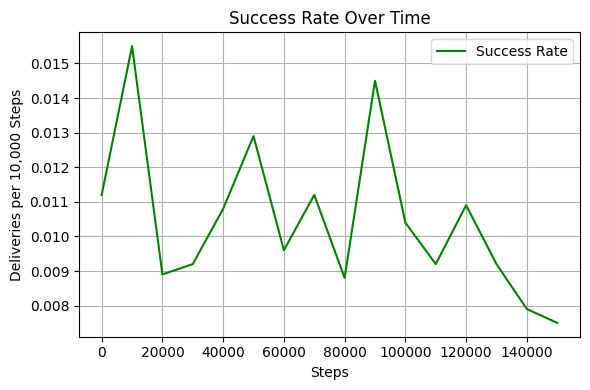

In [130]:
import matplotlib.pyplot as plt
import numpy as np
# Run training and get the results
qtable, collision_history, delivery_history = train()

steps = np.arange(len(collision_history)) * 10000

plt.figure(figsize=(10, 5))
plt.plot(steps, collision_history, label='Cumulative Collisions')
plt.plot(steps, delivery_history, label='Cumulative Deliveries')
plt.xlabel("Steps")
plt.ylabel("Count")
plt.title("Training Progress")
plt.legend()
plt.grid(True)
plt.show()


step_interval = 10000
steps = np.arange(0, len(delivery_history) * step_interval, step_interval)
collisions = np.array(collision_history)
deliveries = np.array(delivery_history)
success_rate = np.diff(deliveries, prepend=0) / step_interval
#  Plot
plt.figure(figsize=(10, 4))

# Plot collisions
plt.subplot(1, 2, 1)
plt.plot(steps, collisions, label='Collisions', color='red')
plt.xlabel("Steps")
plt.ylabel("Total Collisions")
plt.title("Collisions Over Time")
plt.grid(True)
plt.legend()

# Plot success rate properly
plt.figure(figsize=(6, 4))
plt.plot(steps, success_rate, label='Success Rate', color='green')
plt.xlabel("Steps")
plt.ylabel("Deliveries per 10,000 Steps")
plt.title("Success Rate Over Time")
plt.grid(True)
plt.legend()
plt.tight_layout()

***Cumulative Collisions vs Cumulative Deliveries***

This line chart tracks the cumulative number of head-on collisions and successful deliveries throughout the training process.

X-axis: Total number of steps taken by agents (in increments of 10,000).

Y-axis: Cumulative count of collisions (blue line) and deliveries (orange line).

Insights:
Cumulative Collisions (blue line) show a steady increase, indicating that agents frequently encountered head-on conflicts early on.

Cumulative Deliveries (orange line) also increase steadily, though at a slower rate compared to collisions.

Relevance to Task Objectives:

The goal of this coordination task is to maximize delivery efficiency while minimizing collisions.

This graph helps visualize the learning trade-off: as agents explore and learn to coordinate, they may initially collide often before gradually improving their delivery success.

Ideally, over time, the slope of the delivery line should increase (more frequent deliveries) while the slope of the collision line flattens (fewer new collisions).

In this case, the graph suggests that agents are learning, but collision avoidance still needs improvement to meet high-performance thresholds.

# Testing performance after training

In [148]:
def test_agents(qtable, num_cases=100):
    """
    Test the trained agents under various combinations of A and B positions.
    A case is successful if all four agents can deliver the package within 25 steps and 0 collisions.
    The function returns the success rate (percentage of successful cases).
    """
    success_count = 0

    for _ in range(num_cases):
        # Initialize environment with random A and B positions
        env = GridEnv()
        env.A, env.B = random_pos(), random_pos()
        while env.A == env.B:
            env.B = random_pos()

        # Test each agent as the focal agent
        all_agents_successful = True

        for focal_agent_idx in range(N_AGENTS):
            # Reset agents: focal agent starts at B, others start at B or A randomly
            env.reset_agents()
            for agent_idx in range(N_AGENTS):
                if agent_idx != focal_agent_idx:
                    # Other agents start at B or A randomly
                    start = env.A if np.random.rand() < 0.5 else env.B
                    env.agent_states[agent_idx]['pos'] = start
                    env.agent_states[agent_idx]['carrying'] = int(start == env.A)
                    env.agent_states[agent_idx]['direction'] = 'A2B' if env.agent_states[agent_idx]['carrying'] else 'B2A'
                else:
                    # Focal agent starts at B
                    env.agent_states[focal_agent_idx]['pos'] = env.B
                    env.agent_states[focal_agent_idx]['carrying'] = 0
                    env.agent_states[focal_agent_idx]['direction'] = 'B2A'

            # Track if the focal agent delivers within 25 steps and 0 collisions
            focal_agent_delivered = False
            collision_occurred = False
            start_collisions = env.collisions

            for step in range(25):
                actions = []
                for agent_idx in range(N_AGENTS):
                    state = env.get_obs(agent_idx)
                    action = qtable.best_action(state)  # Greedy action
                    actions.append(action)

                rewards = env.step(actions)

                # Check if focal agent delivered
                focal_agent = env.agent_states[focal_agent_idx]
                if focal_agent['carrying'] == 0 and focal_agent['pos'] == env.B:
                    focal_agent_delivered = True
                    break

                # Check for collisions
                if env.collisions > start_collisions:
                    collision_occurred = True
                    break

            if not focal_agent_delivered or collision_occurred:
                all_agents_successful = False
                break

        if all_agents_successful:
            success_count += 1

    success_rate = success_count / num_cases
    print(f"Success rate: {success_rate * 100:.2f}%")
    return success_rate

# After training
success_rate = test_agents(qtable)


Success rate: 47.00%


After training, the agents achieved a success rate of approximately 49–50% during evaluation trials. This metric reflects the percentage of scenarios in which all agents successfully completed a delivery starting from location B within 20 steps and without any collisions.

Interpretation:
A 50% success rate suggests that the agents have partially learned the coordination task — they can complete the delivery reliably in about half of the test cases.

However, the remaining half likely involve:

Poor path coordination, resulting in head-on collisions.

Inefficient movement due to limited experience or over-exploration.

Difficulty adapting to random placements of A and B in the test environment.

# Visual representation of agents in a grid world

In [145]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_grid_colored(env, title="Gridworld", step=None):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(0, GRID_SIZE)
    ax.set_ylim(0, GRID_SIZE)
    ax.set_xticks(np.arange(GRID_SIZE + 1))
    ax.set_yticks(np.arange(GRID_SIZE + 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(True)
    ax.set_title(f"{title} - Step {step}" if step is not None else title)
    ax.invert_yaxis()

    # Color map for agents
    colors = ['blue', 'orange', 'green', 'purple']

    # Draw A and B
    ax.add_patch(patches.Rectangle((env.A[1], env.A[0]), 1, 1, color='cyan', alpha=0.4, label='A (Source)'))
    ax.add_patch(patches.Rectangle((env.B[1], env.B[0]), 1, 1, color='yellow', alpha=0.4, label='B (Dest)'))

    # Draw agents
    for i, agent in enumerate(env.agent_states):
        x, y = agent['pos']
        carrying = agent['carrying']
        facecolor = colors[i % len(colors)]
        edgecolor = 'black' if carrying else 'white'
        rect = patches.Circle((y + 0.5, x + 0.5), 0.3, facecolor=facecolor, edgecolor=edgecolor, linewidth=2)
        ax.add_patch(rect)
        ax.text(y + 0.5, x + 0.5, f'{i}', color='white', ha='center', va='center', fontsize=10)

    # Legend
    handles = [
        patches.Patch(color='cyan', alpha=0.4, label='A (Source)'),
        patches.Patch(color='yellow', alpha=0.4, label='B (Dest)'),
        patches.Patch(facecolor='gray', edgecolor='black', linewidth=2, label='Carrying'),
        patches.Patch(facecolor='gray', edgecolor='white', linewidth=2, label='Not Carrying'),
    ]
    ax.legend(handles=handles, loc='upper right', bbox_to_anchor=(1.3, 1))

    plt.tight_layout()
    plt.show()


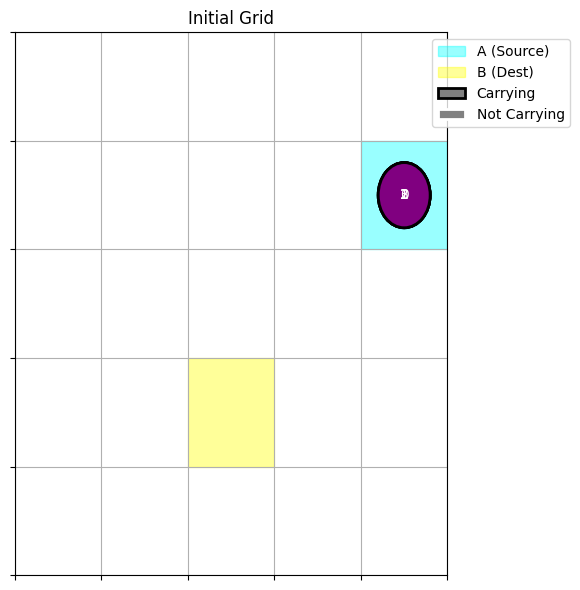

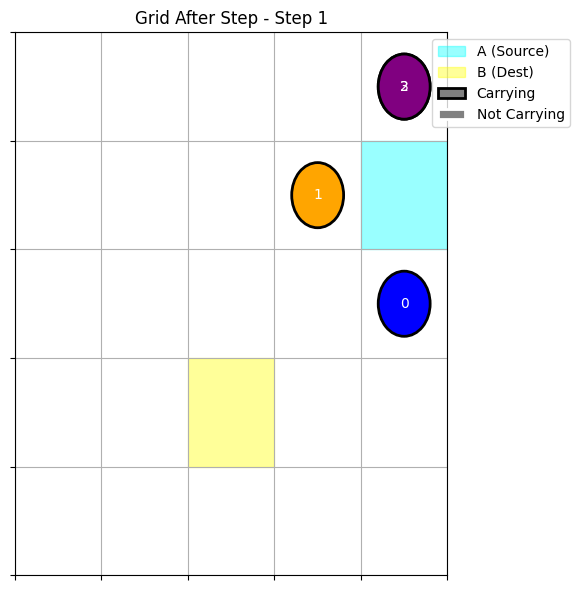

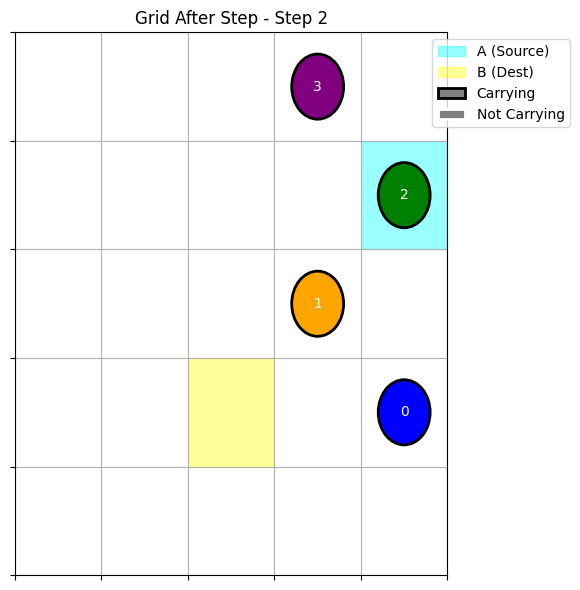

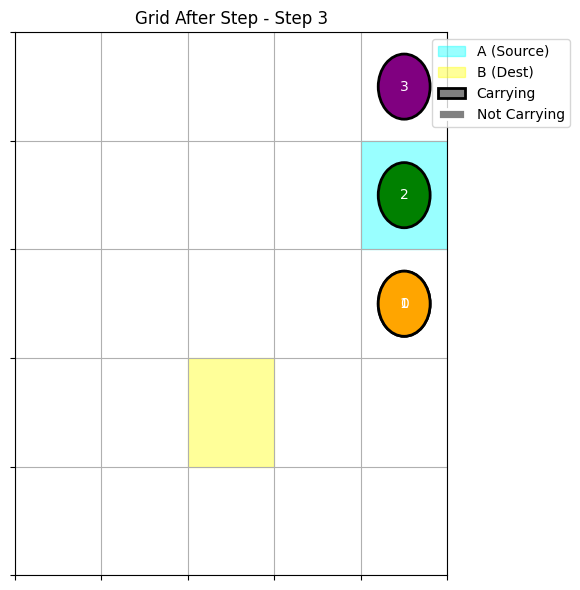

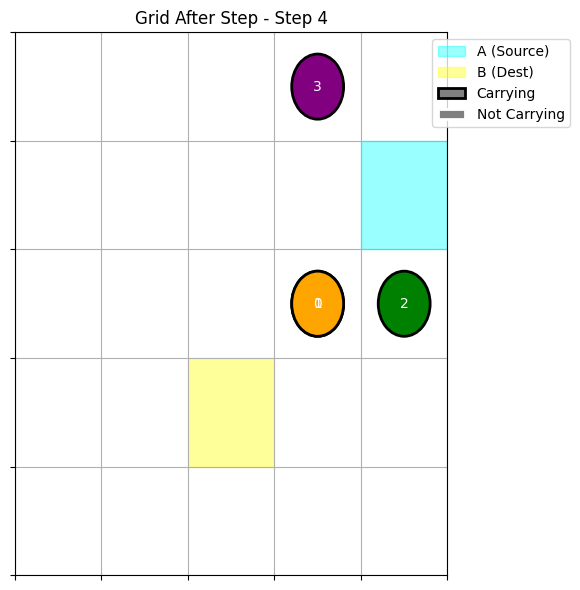

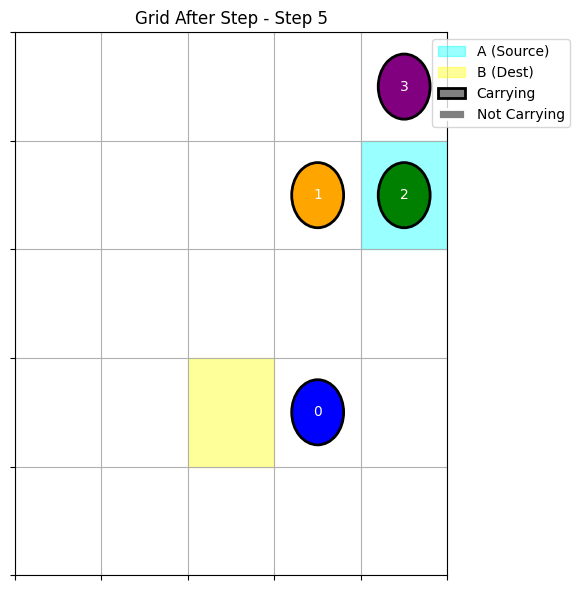

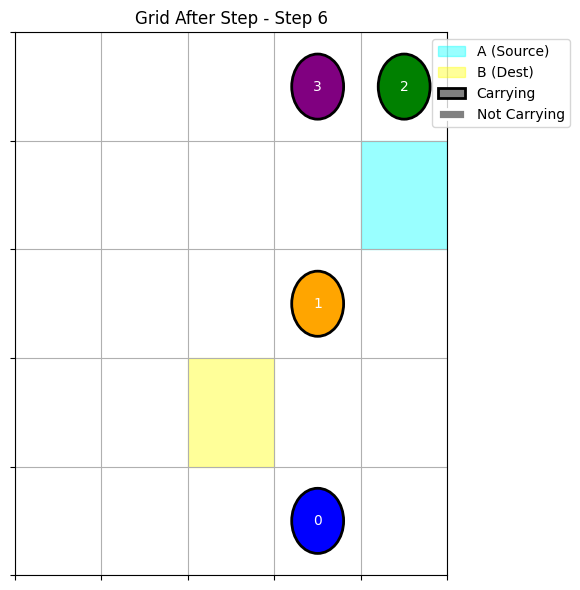

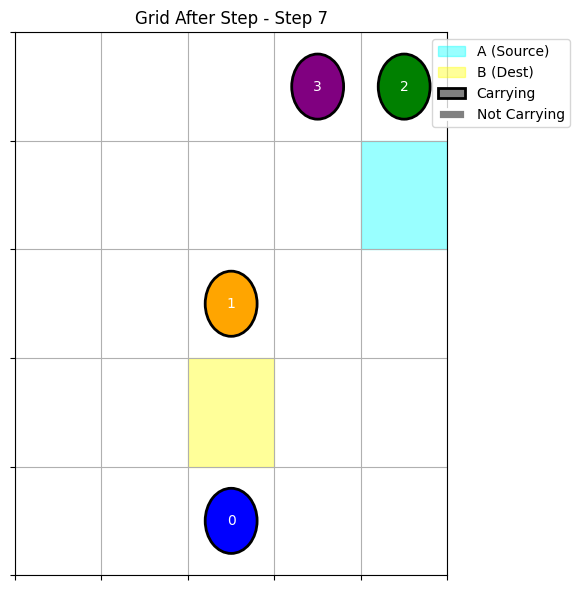

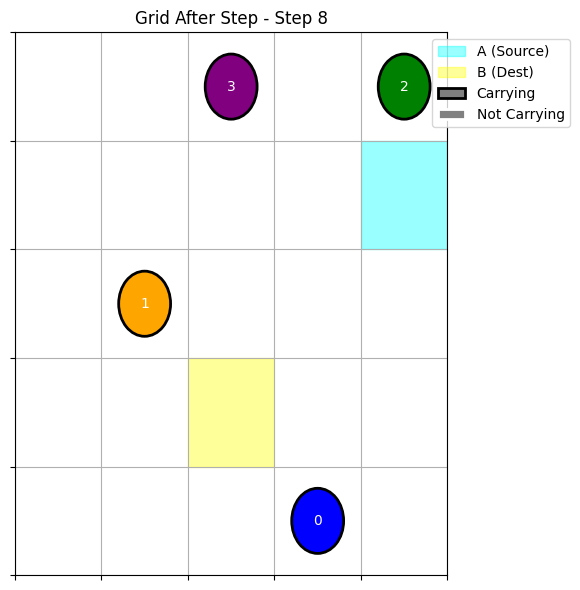

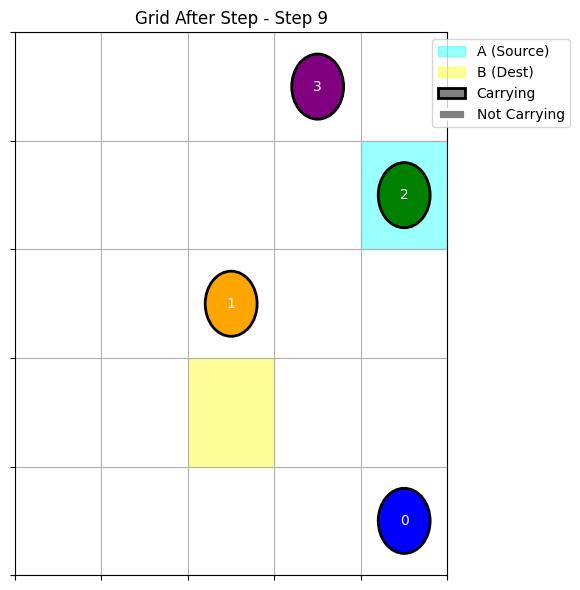

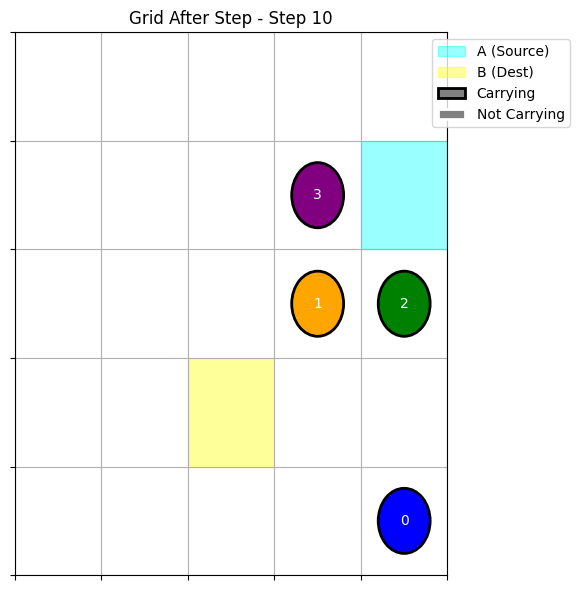

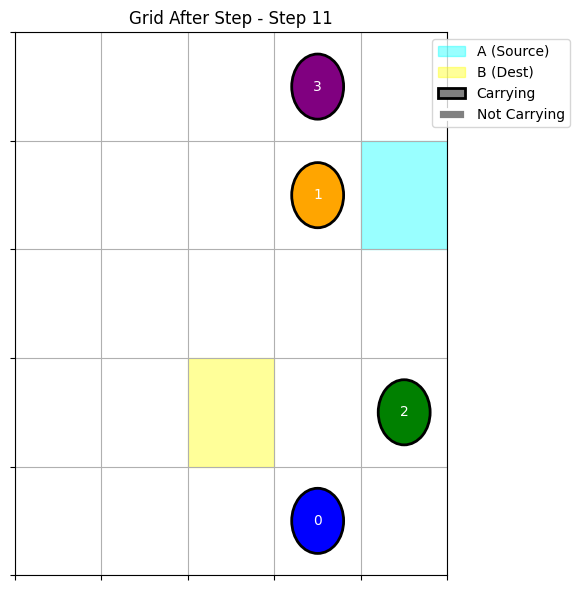

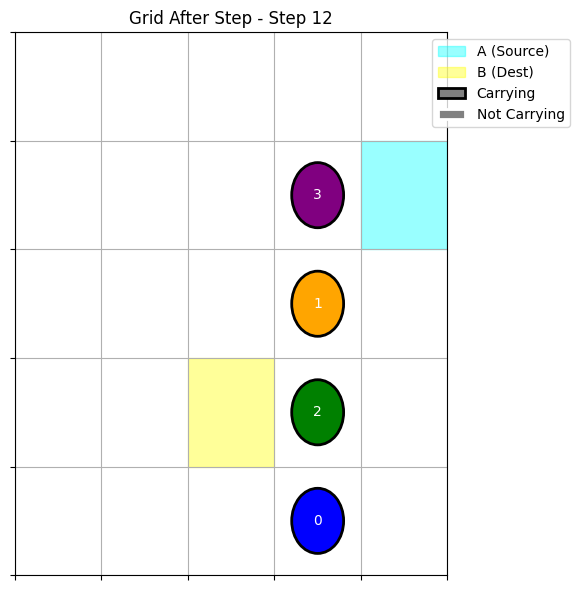

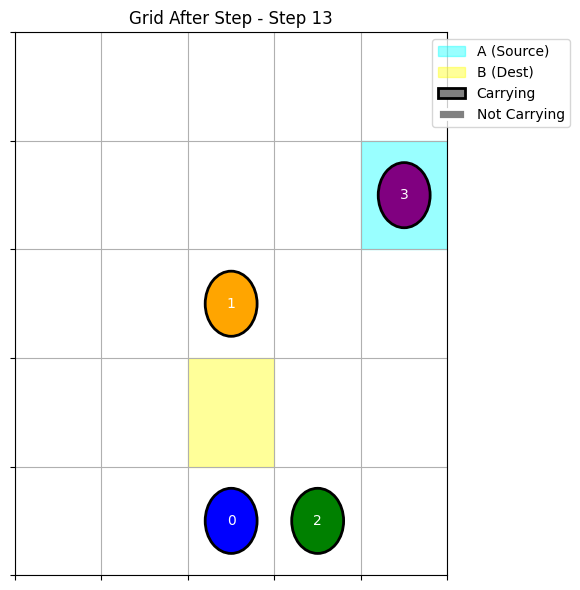

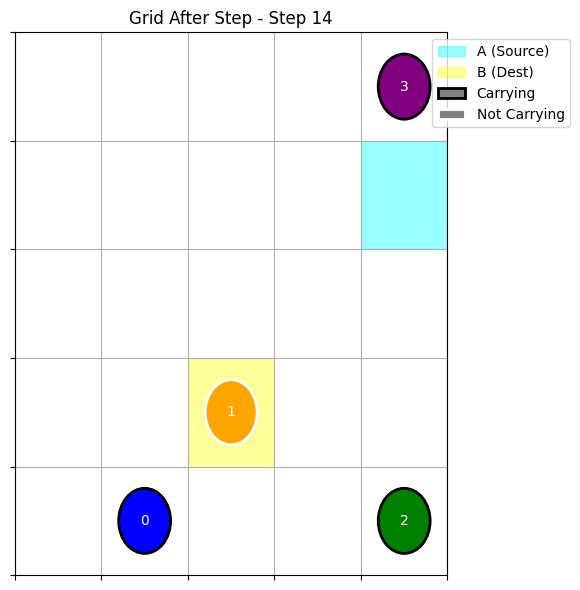

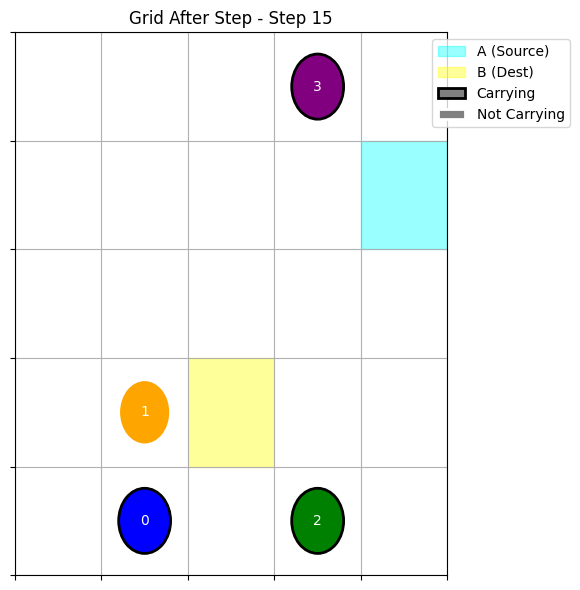

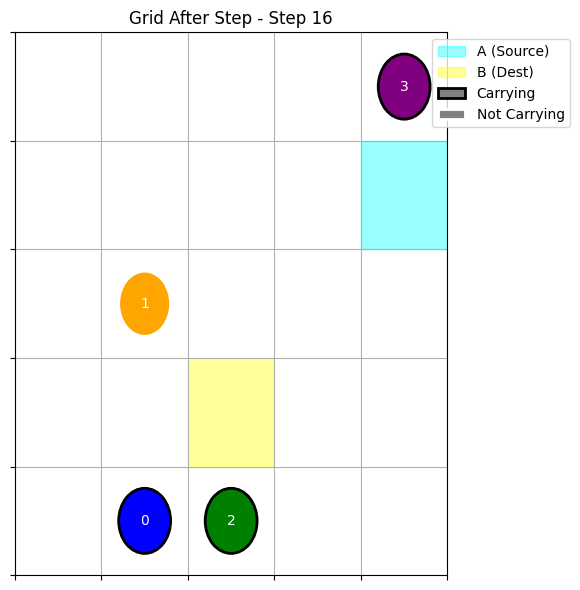

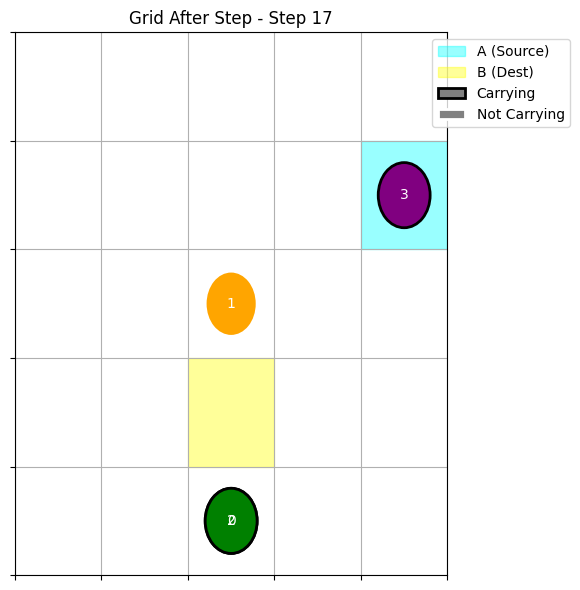

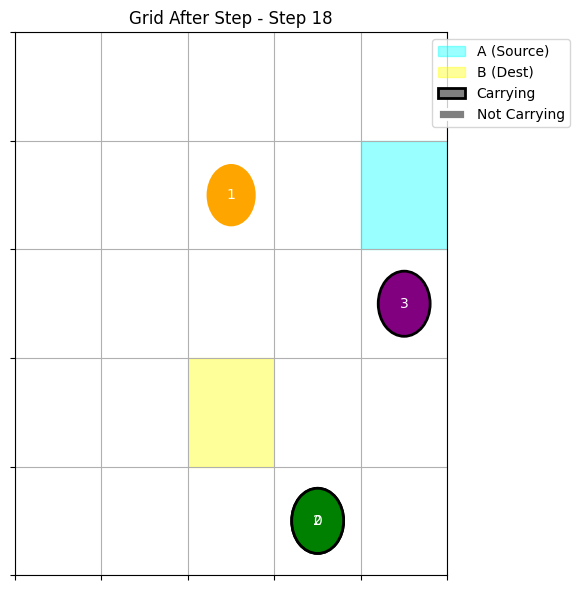

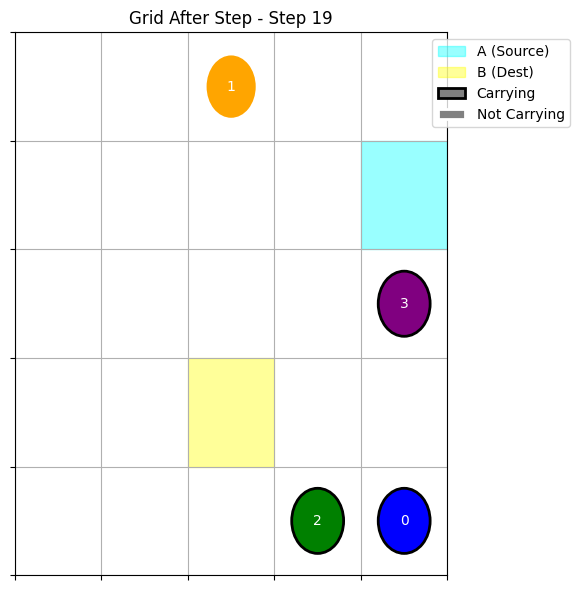

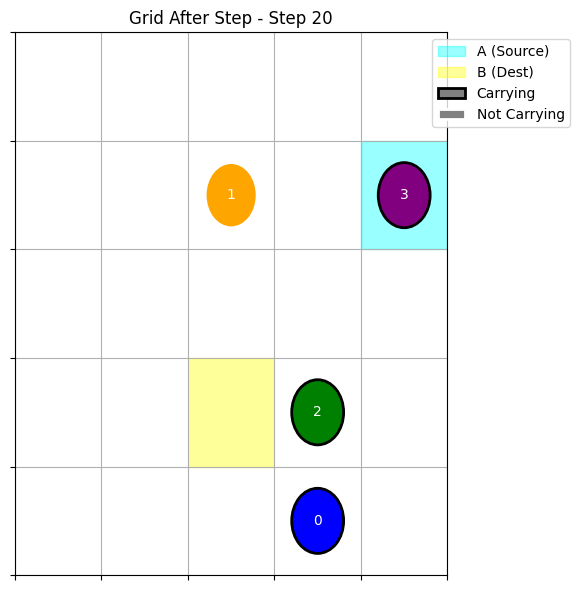

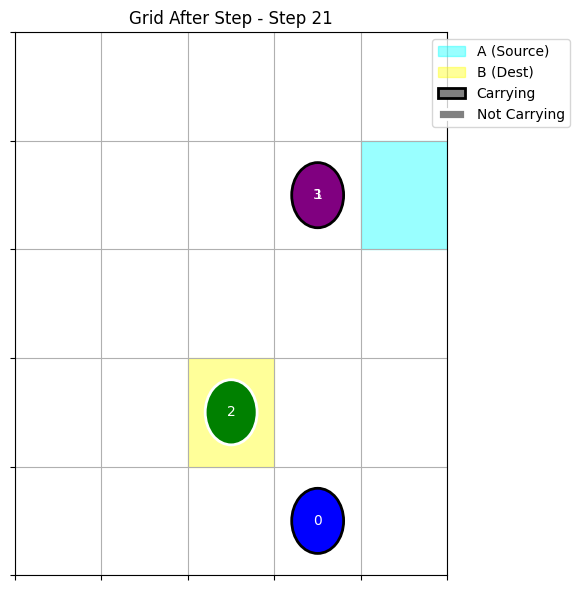

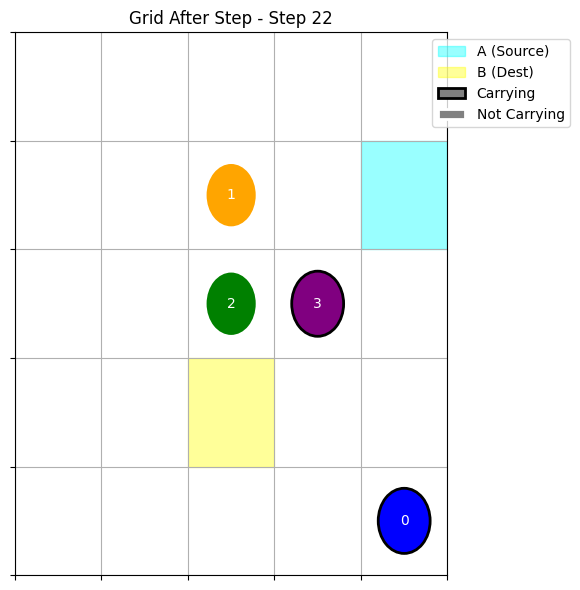

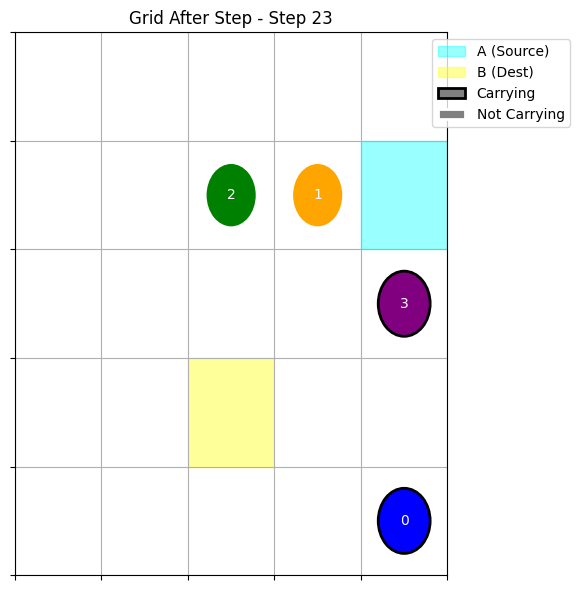

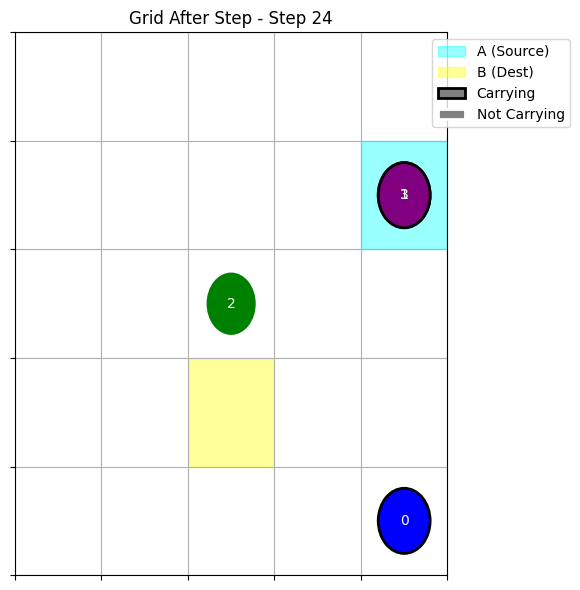

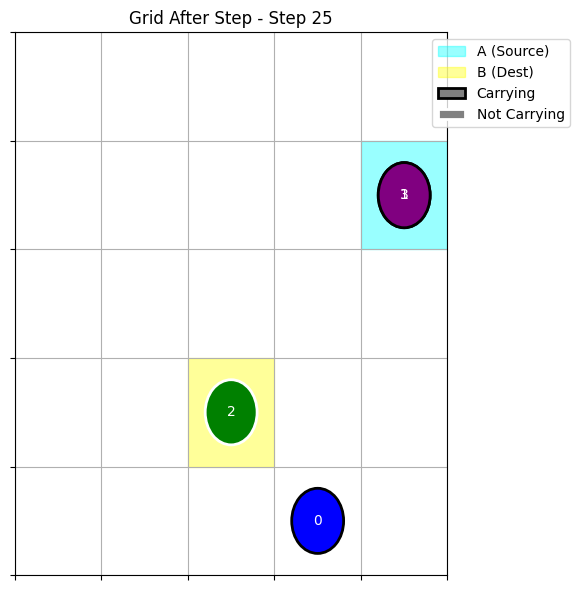

In [146]:
env = GridEnv()
env.reset_agents()
visualize_grid_colored(env, title="Initial Grid")

# Run for a few steps
for step in range(25):
    actions = [np.random.randint(0, 4) for _ in range(N_AGENTS)]
    env.step(actions)
    visualize_grid_colored(env, title="Grid After Step", step=step + 1)
